### Predicting for the House Price Challenge

**Team:** Yuzhou Huang, Mingxi Xiao

Our goal is to predict `SalePrice` for the houses in `test.csv`. Kaggle grades the predictions with RMSE.

We started with the sample notebook from class and made one change at a time. We kept a change only if it made the RMSE go down. Our final model is a `Ridge` model, and it lowers the test RMSE from about \$50,800 to about \$19,700.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error

In [2]:
df = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')
df.shape, test.shape

((1200, 81), (260, 80))

### Baseline: one feature

First we fit the same model as the sample notebook, using only `OverallQual`. We use `train_test_split` so we can check the RMSE on houses the model didn't train on. This is our starting point.

In [3]:
# Same model as the sample notebook, using only OverallQual
X_tr, X_te, y_tr, y_te = train_test_split(df[['OverallQual']], df['SalePrice'], random_state=42)

model = LinearRegression().fit(X_tr, y_tr)
baseline_rmse = np.sqrt(mean_squared_error(y_te, model.predict(X_te)))
baseline_rmse

np.float64(50801.15346567796)

### Target: log(SalePrice)

Most houses sell for \$130k–\$215k, but a few sell for over \$700k. Those few expensive houses can throw off the model. Taking the log of `SalePrice` makes the prices more even, so we predict `np.log(SalePrice)` and turn the predictions back into dollars with `np.exp()`.

In [4]:
# Skew of SalePrice before and after taking the log
df['SalePrice'].skew(), np.log(df['SalePrice']).skew()

(np.float64(1.9672153474609588), np.float64(0.1327137746797166))

### Outliers

One house is very big and has the highest quality rating, but it sold for only \$184,750. It was not finished when it was sold (`SaleCondition` is `Partial`), so its price isn't normal. We drop it so it doesn't pull the model's predictions down for big houses.

In [5]:
# Find the huge house that sold for a very low price
outliers = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
df[outliers][['Id', 'GrLivArea', 'OverallQual', 'SalePrice', 'SaleCondition']]

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition
523,524,4676,10,184750,Partial


In [6]:
df = df[~outliers].reset_index(drop=True)

### Missing Values and Imputation

Same as in class: missing numbers are filled with the mean, and missing categories with the most common value.

In [7]:
df[df.columns[df.isna().sum() > 0]].isna().sum() / len(df)

LotFrontage     0.175146
Alley           0.937448
MasVnrType      0.597998
MasVnrArea      0.005004
BsmtQual        0.026689
BsmtCond        0.026689
BsmtExposure    0.027523
BsmtFinType1    0.026689
BsmtFinType2    0.027523
FireplaceQu     0.470392
GarageType      0.055880
GarageYrBlt     0.055880
GarageFinish    0.055880
GarageQual      0.055880
GarageCond      0.055880
PoolQC          0.996664
Fence           0.810676
MiscFeature     0.960801
dtype: float64

In [8]:
# Same as the sample notebook: mean for numbers, most common value for categories
cat_imputer = SimpleImputer(strategy='most_frequent')
num_imputer = SimpleImputer()

### Feature selection

Some columns say almost the same thing as other columns, or are almost always the same value. We tried dropping columns one at a time and checked `cross_val_score` each time. We kept the 8 drops that lowered the error. The comments explain each one.

In [9]:
# Columns we drop because removing them lowered the error
drop_cols = ['Exterior2nd',   # usually the same as Exterior1st
             'ExterQual',     # very similar to OverallQual
             'SaleType',      # very similar to SaleCondition
             'Condition2',    # almost every house is 'Norm'
             'LandContour',   # almost every house is 'Lvl' (flat)
             'Fence',         # 80% of houses have no fence
             'Electrical',    # almost every house is 'SBrkr'
             'MasVnrType']    # MasVnrArea already gives this information

def prepare(data):
    d = data.drop(columns=['Id'] + drop_cols)
    d['MSSubClass'] = d['MSSubClass'].astype(str)    # this is a house-type code, not a real number
    d['LogLotArea'] = np.log(d['LotArea'])           # a few lots are huge, so the log version helps
    return d

In [10]:
X = prepare(df.drop(columns='SalePrice'))
y = np.log(df['SalePrice'])
X_test = prepare(test)

### Ordinal Encoding vs. OneHotEncoder

The quality columns use the ratings Po, Fa, TA, Gd, Ex. Like in class, we can use `OrdinalEncoder` (turns them into numbers in order) or `OneHotEncoder` (makes a 0/1 column for each rating). We tried both and compared them with `cross_val_score`.

In [11]:
# Quality ratings from worst to best
vals = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ord_cols = ['ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
            'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']

num_cols = X.select_dtypes('number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
ohe_cols = [c for c in cat_cols if c not in ord_cols]

In [12]:
# Fill missing values first, then encode
ohe_pipe = Pipeline([('impute', cat_imputer),
                     ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'))])
ord_pipe = Pipeline([('impute', cat_imputer),
                     ('ord', OrdinalEncoder(categories=[vals] * len(ord_cols)))])

# Option 1: quality columns with OrdinalEncoder
ordinal_transformer = make_column_transformer((ohe_pipe, ohe_cols),
                                              (ord_pipe, ord_cols),
                                              (num_imputer, num_cols))
# Option 2: quality columns with OneHotEncoder
onehot_transformer = make_column_transformer((ohe_pipe, ohe_cols + ord_cols),
                                             (num_imputer, num_cols))

In [13]:
# Compare the two options (0.12 means predictions are off by about 12%)
for name, transformer in [('ordinal', ordinal_transformer), ('one-hot', onehot_transformer)]:
    pipe = Pipeline([('transform', transformer), ('model', LinearRegression())])
    scores = -cross_val_score(pipe, X, y, cv=5, scoring='neg_root_mean_squared_error')
    print(name, round(scores.mean(), 4))

ordinal 0.12


one-hot 0.124


`OrdinalEncoder` had the lower error (0.1200 vs. 0.1240), so we keep it for the quality columns, like in the sample notebook. The other category columns use `OneHotEncoder`.

### Pipeline with Model

We compare `LinearRegression` with `Ridge`. `Ridge` works like `LinearRegression`, but it keeps the coefficients from getting too big. This helps because we have a lot of columns and some of them are very similar. We use `GridSearchCV` to choose `alpha`, which controls how much `Ridge` shrinks the coefficients.

In [14]:
model_pipeline = Pipeline([('transform', ordinal_transformer), ('model', LinearRegression())])

In [15]:
# Ridge needs the number columns on the same scale, so we add StandardScaler.
# GridSearchCV tries different alpha values and picks the best one.
num_scaled = Pipeline([('impute', SimpleImputer()), ('scale', StandardScaler())])
ridge_transformer = make_column_transformer((ohe_pipe, ohe_cols), (ord_pipe, ord_cols), (num_scaled, num_cols))

grid = GridSearchCV(Pipeline([('transform', ridge_transformer), ('model', Ridge())]),
                    param_grid={'model__alpha': [0.1, 1, 3, 10, 30, 100, 300]},
                    cv=5, scoring='neg_root_mean_squared_error')
grid.fit(X, y)

lr_score = -cross_val_score(model_pipeline, X, y, cv=5, scoring='neg_root_mean_squared_error').mean()
print('LinearRegression:', round(lr_score, 4))
print('Ridge:           ', round(-grid.best_score_, 4), grid.best_params_)

LinearRegression: 0.12
Ridge:            0.1134 {'model__alpha': 10}


In [16]:
# Ridge has the lower error, so we use it as the final model
model_pipeline = grid.best_estimator_

In [17]:
# RMSE in dollars on the test split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=42)
lr_pipe = Pipeline([('transform', ordinal_transformer), ('model', LinearRegression())]).fit(X_tr, y_tr)
model_pipeline.fit(X_tr, y_tr)

lr_rmse = np.sqrt(mean_squared_error(np.exp(y_te), np.exp(lr_pipe.predict(X_te))))
test_rmse = np.sqrt(mean_squared_error(np.exp(y_te), np.exp(model_pipeline.predict(X_te))))
print(f'sample model: ${baseline_rmse:,.0f}   LinearRegression: ${lr_rmse:,.0f}   Ridge: ${test_rmse:,.0f}')

sample model: $50,801   LinearRegression: $20,322   Ridge: $19,697


`Ridge` with `alpha = 10` did better than `LinearRegression` (0.1134 vs. 0.1200). On the test split, RMSE went from \$50,801 with the sample model to \$20,322 with `LinearRegression` and \$19,697 with `Ridge`.

In [18]:
# Fit the final model on all of the training data
model_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transform', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](72,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleCondition', 'LogLotArea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,72
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thro

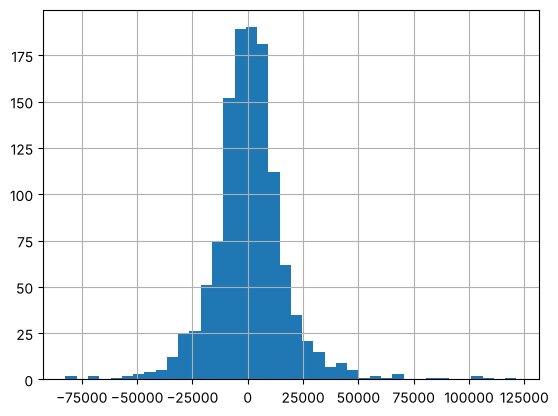

In [19]:
(np.exp(y) - np.exp(model_pipeline.predict(X))).hist(bins=40);

### Predict and save

We fit the final model on all of the training data and predict the test houses. One test house is bigger than every house in the training data, and the model predicts about \$2.7 million for it, which doesn't make sense. So we use `np.clip` to keep every prediction between the lowest and highest prices in the training data.

In [20]:
preds = np.exp(model_pipeline.predict(X_test))

# Keep every prediction between the lowest and highest training prices
print('predictions outside training range:',
      ((preds < df['SalePrice'].min()) | (preds > df['SalePrice'].max())).sum())
preds = np.clip(preds, df['SalePrice'].min(), df['SalePrice'].max())

predictions outside training range: 1


In [21]:
pdf = pd.DataFrame(preds, columns=['SalePrice'])
pdf['Id'] = test.index    # Kaggle uses row numbers 0-259 as the Id
pdf.to_csv('preds.csv', index=False)
pdf.head()

,SalePrice,Id
0,98719.685445,0
1,196122.898850,1
2,131329.252959,2
3,199158.120477,3
4,150881.918260,4


### Summary

| Model | Test RMSE |
|---|---|
| Sample notebook: `OverallQual` only | \$50,801 |
| `LinearRegression` with our changes | \$20,322 |
| Final: `Ridge` | \$19,697 |

What helped the most: using all the columns, predicting log price, and dropping the unfinished house. Adding the log of `LotArea` helped a little. What didn't help: adding new columns (total area, total bathrooms), squared terms, and KNN.

Our Kaggle score is higher than our test RMSE. RMSE squares each error, so one very wrong prediction can make the whole score much worse. The very big test house is the prediction we are least sure about.